In [1]:
import torchvision
import torch
from torchvision import transforms
image_path = './'
transform = transforms.Compose([transforms.ToTensor()])

mnist_dataset = torchvision.datasets.MNIST(root=image_path, train=True, transform=transform, download=True)

from torch.utils.data import Subset

mnist_valid_dataset = Subset(mnist_dataset, torch.arange(10000))

mnist_train_dataset = Subset(mnist_dataset, torch.arange(1000, len(mnist_dataset)))

mnist_test_dataset = torchvision.datasets.MNIST(root=image_path, train=False, transform=transform, download=True)

In [2]:
from torch.utils.data import DataLoader
batch_size = 64
torch.manual_seed(1)

train_d1 = DataLoader(mnist_train_dataset, batch_size, shuffle=True)
valid_d1 = DataLoader(mnist_valid_dataset, batch_size, shuffle=True)

In [3]:
import torch.nn as nn

model = nn.Sequential()

model.add_module('conv1', nn.Conv2d(in_channels=1, out_channels=32, kernel_size=5, padding=2))
model.add_module('relu1', nn.ReLU())
model.add_module('pool1', nn.MaxPool2d(kernel_size=2))

model.add_module('conv2', nn.Conv2d(in_channels=32, out_channels=64, kernel_size=5, padding=2))
model.add_module('relu2', nn.ReLU())
model.add_module('pool2', nn.MaxPool2d(kernel_size=2))

In [4]:
model.add_module('flatten', nn.Flatten())
x = torch.ones((4,1,28,28))

model(x).shape

torch.Size([4, 3136])

In [5]:
model.add_module('fc1', nn.Linear(3136, 1024))
model.add_module('relu3', nn.ReLU())

model.add_module('dropout', nn.Dropout(p=0.5))
model.add_module('fc2', nn.Linear(1024, 10))

In [6]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [7]:

def train(model, num_epochs, train_dl, valid_dl, loss_fn=loss_fn, optimizer=optimizer):
    loss_hist_train = [0] * num_epochs
    accuracy_hist_train = [0] * num_epochs
    loss_hist_valid = [0] * num_epochs
    accuracy_hist_valid = [0] * num_epochs

    for epoch in range(num_epochs):
        model.train()
        for x_batch, y_batch in train_dl:
            pred = model(x_batch)
            loss = loss_fn(pred, y_batch)
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

            loss_hist_train[epoch] += loss.item() * y_batch.size(0)
            is_correct = (torch.argmax(pred, dim=1) == y_batch).float()
            accuracy_hist_train[epoch] += is_correct.sum().item()

        loss_hist_train[epoch] /= len(train_dl.dataset)
        accuracy_hist_train[epoch] /= len(train_dl.dataset)

        model.eval()
        with torch.no_grad():
            for x_batch, y_batch in valid_dl:
                pred = model(x_batch)
                loss = loss_fn(pred, y_batch)
                loss_hist_valid[epoch] += loss.item() * y_batch.size(0)
                is_correct = (torch.argmax(pred, dim=1) == y_batch).float()
                accuracy_hist_valid[epoch] += is_correct.sum().item()

        loss_hist_valid[epoch] /= len(valid_dl.dataset)
        accuracy_hist_valid[epoch] /= len(valid_dl.dataset)

        print(f'Epoch {epoch+1} accuracy: '
              f'{accuracy_hist_train[epoch]:.4f} val_accuracy: '
              f'{accuracy_hist_valid[epoch]:.4f}')

    return loss_hist_train, loss_hist_valid, accuracy_hist_train, accuracy_hist_valid

In [8]:
cuda_available = torch.cuda.is_available()
print(f"Is CUDA available? {cuda_available}")   

Is CUDA available? True


In [9]:
torch.manual_seed(1)
hist = train(model, 10, train_d1, valid_d1)

Epoch 1 accuracy: 0.9543 val_accuracy: 0.9835
Epoch 2 accuracy: 0.9855 val_accuracy: 0.9932
Epoch 3 accuracy: 0.9903 val_accuracy: 0.9927
Epoch 4 accuracy: 0.9917 val_accuracy: 0.9947
Epoch 5 accuracy: 0.9939 val_accuracy: 0.9966
Epoch 6 accuracy: 0.9949 val_accuracy: 0.9947
Epoch 7 accuracy: 0.9953 val_accuracy: 0.9974
Epoch 8 accuracy: 0.9964 val_accuracy: 0.9966
Epoch 9 accuracy: 0.9965 val_accuracy: 0.9985
Epoch 10 accuracy: 0.9970 val_accuracy: 0.9959


In [10]:
pred = model(mnist_test_dataset.data.unsqueeze(1)/255.)

is_correct = (torch.argmax(pred, dim=1) == mnist_test_dataset.targets).float()
print(f'Test accuracy: {is_correct.mean():.4f}')

Test accuracy: 0.9901


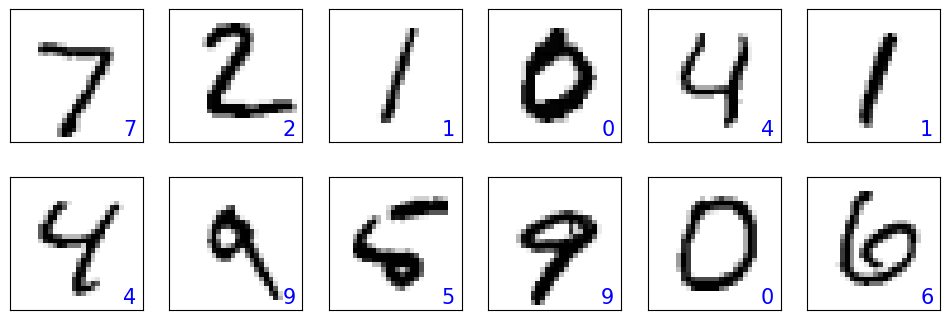

In [11]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(12, 4))

for i in range(12):
    ax = fig.add_subplot(2,6,i+1)
    ax.set_xticks([]); ax.set_yticks([])
    img = mnist_test_dataset[i][0][0,:, :]
    pred = model(img.unsqueeze(0).unsqueeze(1))
    y_pred = torch.argmax(pred)
    ax.imshow(img, cmap='gray_r')
    ax.text(0.9, 0.1, y_pred.item(), size=15, color='blue', horizontalalignment='center',
            verticalalignment='center', transform=ax.transAxes)

plt.show()